# P5 - Deteksi Tepi (Bagian 1 dan 2) | SIMUTEH

- **Nama:** Farhan Fadila  |  **NIM:** 2330511014  |  **SEED:** 1014
- **Data:** dataset sintetis 60 citra (20 sehat, 20 ringan, 20 berat); evaluasi memakai 40 citra berbercak.
- **Praproses:** `src/praproses.py` dan `hasil/param_praproses.json` milik sendiri (median 3 x 3, tanpa gamma, tanpa CLAHE).
- **Ukuran evaluasi:** presisi, recall, F1 tepi dengan toleransi 2 piksel terhadap tepi acuan 1 piksel dari `mask_daun` dan `mask_bercak`.

Cakupan notebook ini: Bagian 1 (gradien dan operator tepi, P1.1-P1.5) dan Bagian 2 (Canny dan keputusan pemakaian tepi, P2.1-P2.6).

## Bagian 1. Gradien Citra dan Operator Tepi

### Langkah 1.1 Lembar hitung manual

Potongan 3 x 3 kanal R: `A = [[52,55,180],[50,58,185],[54,60,190]]`. Kernel diterapkan sebagai korelasi (tidak dibalik).

**(a) Sobel, piksel tengah (58)**

- Gx = (-1*52 + 0*55 + 1*180) + (-2*50 + 0*58 + 2*185) + (-1*54 + 0*60 + 1*190) = 128 + 270 + 136 = **534**
- Gy = (-1*52 - 2*55 - 1*180) + (0) + (1*54 + 2*60 + 1*190) = -342 + 364 = **22**
- |G| = akar(534^2 + 22^2) = akar(285.156 + 484) = akar(285.640) = **534,45**
- |Gx| + |Gy| = 534 + 22 = **556**
- theta = atan2(22, 534) = **2,36 derajat**

**(b) Prewitt**

- Gx = (180-52) + (185-50) + (190-54) = 128 + 135 + 136 = **399**
- Gy = (54+60+190) - (52+55+180) = 304 - 287 = **17**
- |G| = akar(399^2 + 17^2) = akar(159.490) = **399,36**;  |Gx|+|Gy| = 416;  theta = **2,44 derajat**
- Perbandingan: 534,45 / 399,36 = **1,338** (mendekati 4/3 karena jumlah bobot Sobel 1+2+1 = 4, Prewitt 1+1+1 = 3).

**(c) Laplacian** = 55 + 50 + 185 + 60 - 4*58 = 350 - 232 = **+118**.
Tanda **positif**: jumlah tetangga (rerata 87,5) lebih besar daripada nilai pusat (58), artinya pusat **lebih gelap** daripada sekitarnya, yaitu berada di kaki gelap (sisi daun) dari lereng tepi. Tepi sebenarnya ada di perlintasan nol antara respons positif (sisi gelap) dan negatif (sisi terang).

**(d) Arah tepi.** Arah gradien = 2,4 derajat (hampir horizontal, menunjuk ke kanan, ke sisi terang/bercak). Tepi tegak lurus terhadap gradien, sehingga arah tepi = 2,4 + 90 = **sekitar 92,4 derajat, yaitu hampir vertikal**: garis batas antara daun (kiri, gelap) dan bercak (kanan, terang) berjalan tegak.

Verifikasi dengan kode:

In [1]:
import numpy as np
A = np.array([[52, 55, 180], [50, 58, 185], [54, 60, 190]], float)
sobel_kx = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], float)
prew_kx = np.array([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]], float)
lap = np.array([[0, 1, 0], [1, -4, 1], [0, 1, 0]], float)

def hitung(nama, kx):
    ky = kx.T
    gx, gy = (A * kx).sum(), (A * ky).sum()          # korelasi: kernel tidak dibalik
    print(f"{nama:8s} Gx={gx:.0f}  Gy={gy:.0f}  |G|={np.hypot(gx, gy):.2f}  "
          f"|Gx|+|Gy|={abs(gx) + abs(gy):.0f}  theta={np.degrees(np.arctan2(gy, gx)):.2f} derajat")
    return gx, gy

hitung("Sobel", sobel_kx)
hitung("Prewitt", prew_kx)
print("Laplacian =", (A * lap).sum(), "| jumlah tetangga 4 =", A[0,1]+A[1,0]+A[1,2]+A[2,1], "| 4 x pusat =", 4 * A[1,1])

Sobel    Gx=534  Gy=22  |G|=534.45  |Gx|+|Gy|=556  theta=2.36 derajat
Prewitt  Gx=399  Gy=17  |G|=399.36  |Gx|+|Gy|=416  theta=2.44 derajat
Laplacian = 118.0 | jumlah tetangga 4 = 350.0 | 4 x pusat = 232.0


### Langkah 1.2 Persiapan dan gradien Sobel

Kode 1.1: modul, data, praproses, dan tepi acuan.

PARAM: {'lebar': 640, 'gamma': 1.0, 'clahe_clip': 0.0, 'clahe_tile': 8, 'penapis': 'median', 'kernel': 3, 'sigma': 1.0, 'tajam_k': 0.0}
ukuran citra: (480, 640, 3) | piksel tepi acuan: 2238


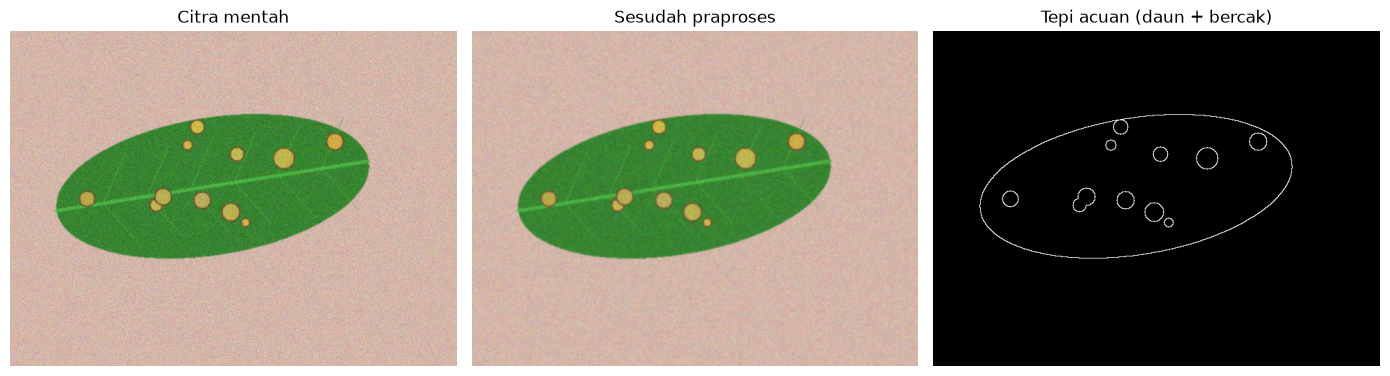

In [2]:
import sys, json
sys.path.append("../src")
import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
from utils_cv import baca, tampil
from praproses import praproses
from utils_tepi import tepi_acuan, skor_tepi, iou, mask_daun_awal, bercak_awal

pd.set_option("display.width", 160); pd.set_option("display.max_columns", 20)
PARAM = json.load(open("../hasil/param_praproses.json"))   # hasil Evaluasi P1-P4
label = pd.read_csv("../data/sintetis/label.csv")

def muat(nama):
    img = baca(f"../data/sintetis/citra/{nama}")
    md = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0)
    mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)
    return img, md, mb

img, md, mb = muat("teh_041.png")
pra = praproses(img, PARAM)
acuan = cv2.bitwise_or(tepi_acuan(md), tepi_acuan(mb))
tampil([img, pra, acuan], ["Citra mentah", "Sesudah praproses", "Tepi acuan (daun + bercak)"])
print("PARAM:", PARAM)
print("ukuran citra:", img.shape, "| piksel tepi acuan:", int((acuan > 0).sum()))

Kode 1.2: gradien Sobel manual dengan `cv2.filter2D`, diperiksa terhadap `cv2.Sobel` (selisih 0,0 berarti hitung manual identik dengan pustaka).

selisih maks gx manual vs cv2.Sobel: 0.0
magnitudo maks: 575.5


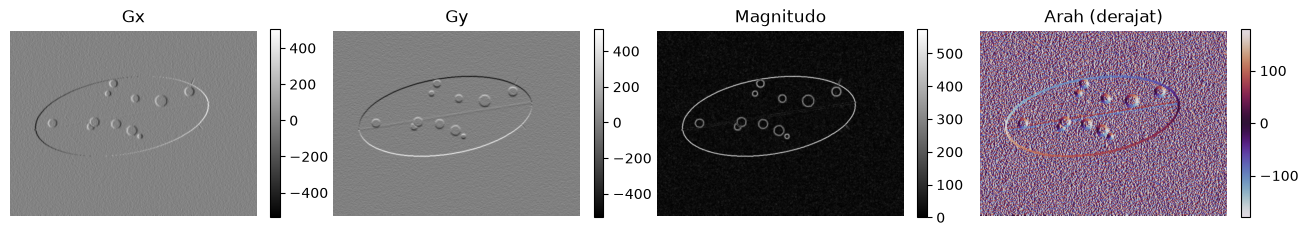

In [3]:
g = pra[:, :, 2].astype(np.float32)          # kanal R hasil praproses
kx = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], np.float32)
ky = kx.T
gx = cv2.filter2D(g, cv2.CV_32F, kx)         # turunan arah x (tepi vertikal)
gy = cv2.filter2D(g, cv2.CV_32F, ky)         # turunan arah y (tepi horizontal)
mag = np.sqrt(gx ** 2 + gy ** 2)
arah = np.degrees(np.arctan2(gy, gx))

# bandingkan dengan fungsi pustaka
gx_cv = cv2.Sobel(g, cv2.CV_32F, 1, 0, ksize=3)
print("selisih maks gx manual vs cv2.Sobel:", np.abs(gx - gx_cv).max())
print("magnitudo maks:", mag.max().round(1))

plt.figure(figsize=(16, 3.6))
for i, (c, jd) in enumerate([(gx, "Gx"), (gy, "Gy"), (mag, "Magnitudo"), (arah, "Arah (derajat)")]):
    plt.subplot(1, 4, i + 1)
    plt.imshow(c, cmap="twilight" if i == 3 else "gray"); plt.title(jd); plt.axis("off"); plt.colorbar(fraction=0.035)
plt.savefig("../hasil/p5_gradien_sobel.png", dpi=130, bbox_inches="tight")

### Langkah 1.3 Empat operator pada satu citra (kanal R sesudah praproses, teh_041)

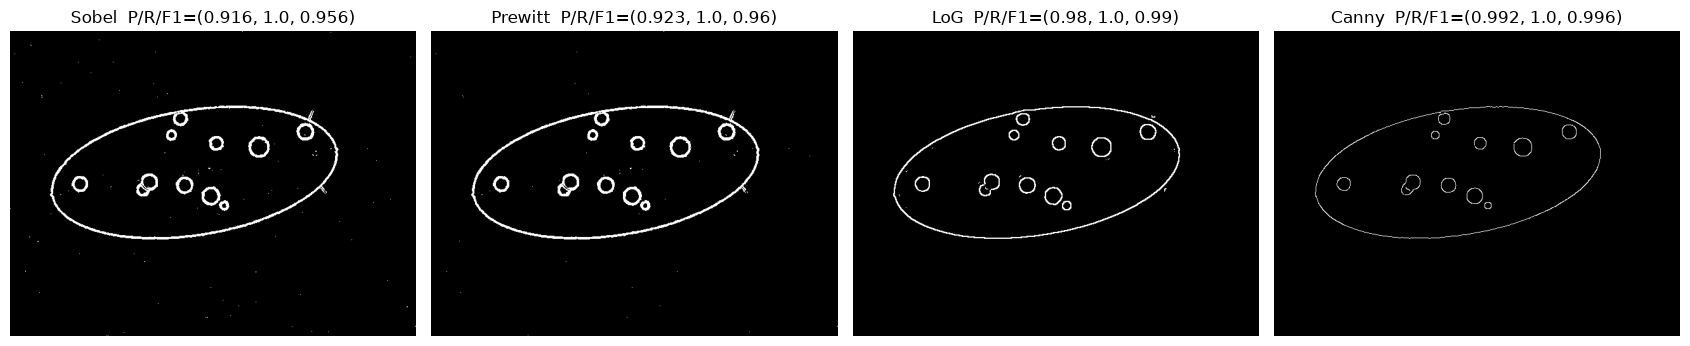

In [4]:
def tepi_sobel(g, T=100):
    g = g.astype(np.float32)
    m = np.hypot(cv2.Sobel(g, cv2.CV_32F, 1, 0), cv2.Sobel(g, cv2.CV_32F, 0, 1))
    return ((m > T) * 255).astype(np.uint8)

def tepi_prewitt(g, T=75):
    kx = np.array([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]], np.float32)
    g = g.astype(np.float32)
    m = np.hypot(cv2.filter2D(g, -1, kx), cv2.filter2D(g, -1, kx.T))
    return ((m > T) * 255).astype(np.uint8)

def tepi_log(g, sigma=3.0, frac=0.2):
    """Laplacian of Gaussian: tepi = perlintasan nol yang cukup kuat."""
    L = cv2.Laplacian(cv2.GaussianBlur(g.astype(np.float32), (0, 0), sigma), cv2.CV_32F)
    mn, mx = cv2.erode(L, np.ones((3, 3))), cv2.dilate(L, np.ones((3, 3)))
    return (((mn < 0) & (mx > 0) & (mx - mn > frac * np.abs(L).max())) * 255).astype(np.uint8)

def tepi_canny(g, lo=30, hi=90, sigma=2.0):
    if sigma > 0:
        g = cv2.GaussianBlur(g, (0, 0), sigma)
    return cv2.Canny(g, lo, hi)

metode = {"Sobel": tepi_sobel, "Prewitt": tepi_prewitt, "LoG": tepi_log, "Canny": tepi_canny}
g = pra[:, :, 2]
hasil = {nm: f(g) for nm, f in metode.items()}
tampil(list(hasil.values()), [f"{nm}  P/R/F1={skor_tepi(e, acuan)}" for nm, e in hasil.items()],
       ukuran=(17, 3.6))
plt.savefig("../hasil/p5_empat_operator.png", dpi=130, bbox_inches="tight")

**Gambar 2.** Tepi hasil Sobel, Prewitt, LoG, dan Canny pada teh_041 kanal R sesudah praproses (`hasil/p5_empat_operator.png`).

### Langkah 1.4 Perbandingan menyeluruh (40 citra berbercak)

In [5]:
baris = []
for _, d in label[label.kelas != "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)
    ac = cv2.bitwise_or(tepi_acuan(md), tepi_acuan(mb))
    for sumber, im in [("mentah", img), ("praproses", praproses(img, PARAM))]:
        for kanal, g in [("Gray", cv2.cvtColor(im, cv2.COLOR_BGR2GRAY)), ("R", im[:, :, 2])]:
            for nm, f in metode.items():
                p, r, f1 = skor_tepi(f(g), ac)
                baris.append([d.kondisi_cahaya, sumber, kanal, nm, p, r, f1])
tabel_tepi = pd.DataFrame(baris, columns=["kondisi", "sumber", "kanal", "metode", "P", "R", "F1"])
ringkas = tabel_tepi.groupby(["sumber", "kanal", "metode"])[["P", "R", "F1"]].mean().round(3)
print(ringkas)
tabel_tepi.to_csv("../hasil/p5_tabel_tepi.csv", index=False)

                             P      R     F1
sumber    kanal metode                      
mentah    Gray  Canny    0.747  0.756  0.750
                LoG      0.633  0.997  0.769
                Prewitt  0.766  0.974  0.850
                Sobel    0.726  0.978  0.823
          R     Canny    0.986  0.990  0.988
                LoG      0.902  0.997  0.938
                Prewitt  0.526  0.997  0.634
                Sobel    0.467  0.997  0.575
praproses Gray  Canny    0.754  0.748  0.750
                LoG      0.645  0.997  0.777
                Prewitt  0.907  0.842  0.828
                Sobel    0.904  0.859  0.845
          R     Canny    0.989  0.984  0.986
                LoG      0.915  0.997  0.945
                Prewitt  0.956  0.988  0.971
                Sobel    0.954  0.989  0.971


**Tabel 6.** Rerata F1 tepi per operator, kanal, dan sumber citra:

In [6]:
# Tabel 6: rerata F1 tepi per operator, kanal, dan sumber citra
urut = ["Sobel", "Prewitt", "LoG", "Canny"]
t6 = (tabel_tepi.groupby(["metode", "sumber", "kanal"]).F1.mean().unstack(["sumber", "kanal"])
      .loc[urut, [("mentah", "Gray"), ("mentah", "R"), ("praproses", "Gray"), ("praproses", "R")]].round(3))
t6.columns = ["Mentah, Gray", "Mentah, R", "Praproses, Gray", "Praproses, R"]
t6.index = ["Sobel (T = 100)", "Prewitt (T = 75)", "LoG (sigma 3)", "Canny (30/90, sigma 2)"]
t6.index.name = "Operator"
t6.to_csv("../hasil/p5_tabel6_f1.csv")
print(t6)

                        Mentah, Gray  Mentah, R  Praproses, Gray  Praproses, R
Operator                                                                      
Sobel (T = 100)                0.823      0.575            0.845         0.971
Prewitt (T = 75)               0.850      0.634            0.828         0.971
LoG (sigma 3)                  0.769      0.938            0.777         0.945
Canny (30/90, sigma 2)         0.750      0.988            0.750         0.986


### Langkah 1.5 (kerjakan sendiri) Grafik F1 per kondisi cahaya

metode          Sobel  Prewitt    LoG  Canny
kondisi                                     
normal          0.966    0.966  0.978  0.989
gelap           0.949    0.944  0.985  0.989
terang          0.988    0.990  0.974  0.996
kontras_rendah  0.969    0.970  0.818  0.965
bayangan        0.982    0.983  0.969  0.993


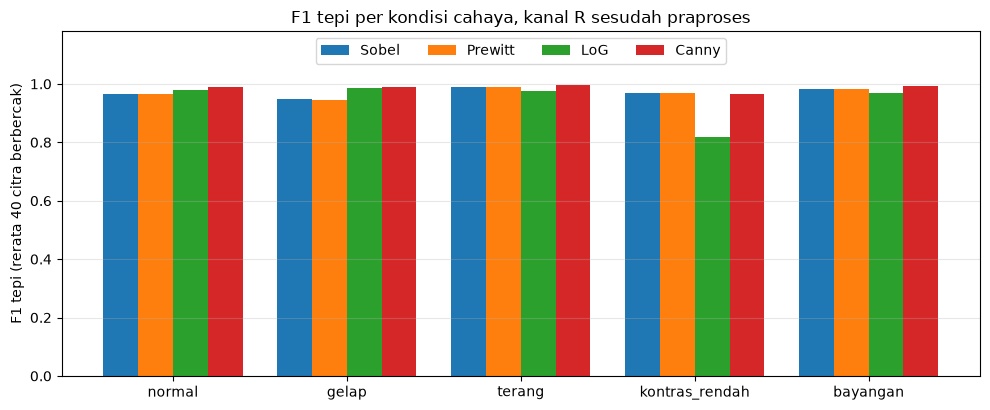

In [7]:
# Langkah 1.5 (kerjakan sendiri): F1 per kondisi cahaya, kanal R sesudah praproses
urut_kondisi = ["normal", "gelap", "terang", "kontras_rendah", "bayangan"]
f1_kond = (tabel_tepi[(tabel_tepi.sumber == "praproses") & (tabel_tepi.kanal == "R")]
           .groupby(["kondisi", "metode"]).F1.mean().unstack("metode").loc[urut_kondisi, urut])
print(f1_kond.round(3))

fig, ax = plt.subplots(figsize=(10, 4.2))
lebar = 0.2
for i, nm in enumerate(urut):
    ax.bar(np.arange(len(urut_kondisi)) + (i - 1.5) * lebar, f1_kond[nm], lebar, label=nm)
ax.set_xticks(np.arange(len(urut_kondisi))); ax.set_xticklabels(urut_kondisi)
ax.set_ylabel("F1 tepi (rerata 40 citra berbercak)"); ax.set_ylim(0, 1.18)
ax.set_title("F1 tepi per kondisi cahaya, kanal R sesudah praproses")
ax.legend(ncol=4, loc="upper center"); ax.grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.savefig("../hasil/p5_f1_kondisi.png", dpi=150)

**Gambar 3.** F1 tepi per kondisi cahaya, kanal R sesudah praproses (`hasil/p5_f1_kondisi.png`).

### Data pendukung untuk P1.2 - P1.5

In [8]:
# Pendukung P1.2: magnitudo Sobel vs Prewitt pada tepi yang sama, dan dampak ambang T yang sama
g32 = pra[:, :, 2].astype(np.float32)
m_sobel = np.hypot(cv2.Sobel(g32, cv2.CV_32F, 1, 0), cv2.Sobel(g32, cv2.CV_32F, 0, 1))
kxp = np.array([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]], np.float32)
m_prew = np.hypot(cv2.filter2D(g32, -1, kxp), cv2.filter2D(g32, -1, kxp.T))
tp = tepi_acuan(md) > 0
print("rasio magnitudo Sobel/Prewitt di tepi daun (teh_041): median =", round(float(np.median(m_sobel[tp] / np.maximum(m_prew[tp], 1e-6))), 3))
print("teori untuk tepi tegas: bobot Sobel (1+2+1)=4 vs Prewitt (1+1+1)=3 -> 4/3 =", round(4/3, 3))

baris = []
for _, d in label[label.kelas != "sehat"].iterrows():
    img_, md_, mb_ = muat(d.nama_file)
    ac_ = cv2.bitwise_or(tepi_acuan(md_), tepi_acuan(mb_))
    gg = praproses(img_, PARAM)[:, :, 2]
    for T in [75, 100]:
        baris.append(["Sobel", T] + list(skor_tepi(tepi_sobel(gg, T), ac_)))
        baris.append(["Prewitt", T] + list(skor_tepi(tepi_prewitt(gg, T), ac_)))
t_T = pd.DataFrame(baris, columns=["operator", "T", "P", "R", "F1"]).groupby(["operator", "T"]).mean().round(3)
print(t_T)

rasio magnitudo Sobel/Prewitt di tepi daun (teh_041): median = 1.369
teori untuk tepi tegas: bobot Sobel (1+2+1)=4 vs Prewitt (1+1+1)=3 -> 4/3 = 1.333
                  P      R     F1
operator T                       
Prewitt  75   0.956  0.988  0.971
         100  0.977  0.926  0.943
Sobel    75   0.834  0.997  0.903
         100  0.954  0.989  0.971


In [9]:
# Pendukung P1.3: Kontras Bercak (KB) per kanal dari Evaluasi P1-P4 (berat dan ringan)
kb_b = pd.read_csv("../hasil/b2_kb_kanal.csv").set_index("kondisi")[["Gray", "R"]]
kb_r = pd.read_csv("../hasil/b2_kb_kanal_ringan.csv").set_index("kondisi")[["Gray", "R"]]
kb = kb_b.join(kb_r, lsuffix="_berat", rsuffix="_ringan").loc[urut_kondisi]
print("KB (hasil B2):"); print(kb)
f1_kanal = (tabel_tepi[tabel_tepi.sumber == "praproses"].groupby(["kondisi", "kanal", "metode"]).F1.mean()
            .unstack(["kanal", "metode"]).loc[urut_kondisi].round(3))
print("\nF1 per kondisi (praproses):"); print(f1_kanal)
print("\nrerata F1 R - Gray per operator (praproses):")
print((tabel_tepi[(tabel_tepi.sumber == "praproses")].groupby(["metode", "kanal"]).F1.mean().unstack("kanal")
       .assign(selisih_R_minus_Gray=lambda x: x.R - x.Gray).round(3)))

KB (hasil B2):
                Gray_berat  R_berat  Gray_ringan  R_ringan
kondisi                                                   
normal                4.09     8.89         3.02      8.65
gelap                 4.25    11.98         2.75      8.79
terang                4.42     7.51         2.50      5.40
kontras_rendah        1.90     3.35         1.56      3.49
bayangan              1.62     5.36         1.30      4.43

F1 per kondisi (praproses):
kanal            Gray                            R                      
metode          Canny    LoG Prewitt  Sobel  Canny    LoG Prewitt  Sobel
kondisi                                                                 
normal          0.919  0.788   0.906  0.902  0.989  0.978   0.966  0.966
gelap           0.921  0.780   0.873  0.872  0.989  0.985   0.944  0.949
terang          0.966  0.824   0.990  0.990  0.996  0.974   0.990  0.988
kontras_rendah  0.000  0.662   0.435  0.517  0.965  0.818   0.970  0.969
bayangan        0.944  0.832   0

In [10]:
# Pendukung P1.4: pengaruh praproses (sesudah - mentah) pada P, R, F1 per operator dan kanal
rata = tabel_tepi.groupby(["metode", "kanal", "sumber"])[["P", "R", "F1"]].mean().unstack("sumber")
delta = pd.DataFrame({u: rata[(u, "praproses")] - rata[(u, "mentah")] for u in ["P", "R", "F1"]}).round(3)
print("selisih (praproses - mentah):"); print(delta)
dk = (tabel_tepi.groupby(["kondisi", "kanal", "metode", "sumber"]).F1.mean().unstack("sumber")
      .assign(delta=lambda x: x.praproses - x.mentah).round(3))
print("\nkombinasi dengan delta F1 paling negatif:"); print(dk.sort_values("delta").head(6))
print("\nmentah vs praproses per kondisi, Canny, kanal R:"); print(dk.xs(("R", "Canny"), level=("kanal", "metode")).loc[urut_kondisi])
pr = (tabel_tepi[(tabel_tepi.kondisi == "kontras_rendah") & (tabel_tepi.kanal == "Gray") & (tabel_tepi.metode.isin(["Prewitt", "Sobel"]))]
      .groupby(["metode", "sumber"])[["P", "R", "F1"]].mean().round(3))
print("\nkontras_rendah, kanal Gray (P, R, F1):"); print(pr)

selisih (praproses - mentah):
                   P      R     F1
metode  kanal                     
Canny   Gray   0.007 -0.007  0.000
        R      0.003 -0.006 -0.001
LoG     Gray   0.012 -0.001  0.009
        R      0.013 -0.001  0.007
Prewitt Gray   0.141 -0.132 -0.022
        R      0.429 -0.009  0.337
Sobel   Gray   0.178 -0.119  0.022
        R      0.487 -0.008  0.396

kombinasi dengan delta F1 paling negatif:
sumber                        mentah  praproses  delta
kondisi        kanal metode                           
kontras_rendah Gray  Prewitt   0.817      0.435 -0.382
                     Sobel     0.777      0.517 -0.260
               R     Canny     0.978      0.965 -0.013
terang         Gray  Canny     0.976      0.966 -0.010
normal         Gray  Canny     0.920      0.919 -0.001
kontras_rendah Gray  Canny     0.000      0.000  0.000

mentah vs praproses per kondisi, Canny, kanal R:
sumber          mentah  praproses  delta
kondisi                                 
norma

   sigma  frac  piksel_tepi      P    R     F1
0    1.0  0.00       268812  0.018  1.0  0.036
1    1.0  0.05       267321  0.018  1.0  0.036
2    1.0  0.20       101273  0.048  1.0  0.092
3    2.0  0.00       193581  0.023  1.0  0.044
4    2.0  0.05       169835  0.026  1.0  0.050
5    2.0  0.20         7420  0.590  1.0  0.742
6    3.0  0.00       137094  0.032  1.0  0.063
7    3.0  0.05        18777  0.236  1.0  0.381
8    3.0  0.20         4496  0.980  1.0  0.990
piksel tepi acuan: 2238


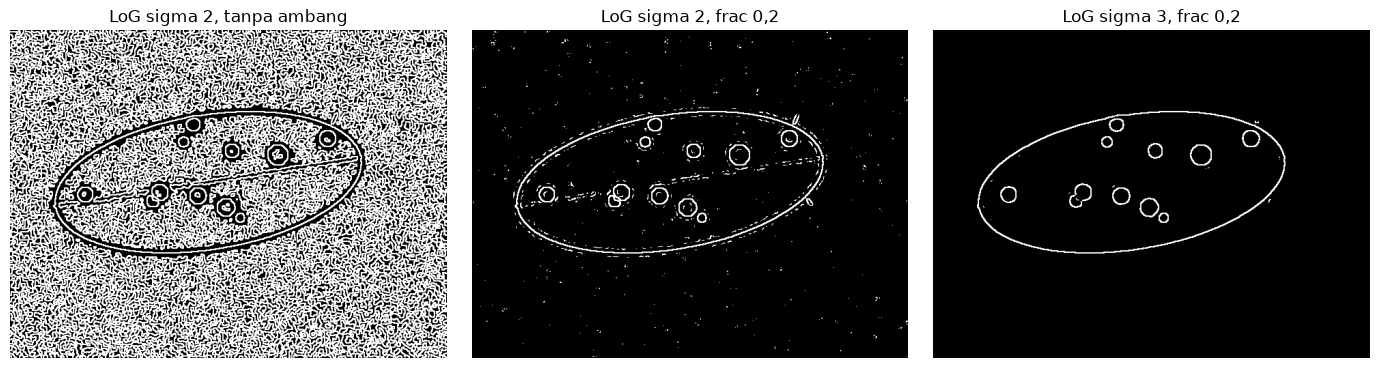

In [11]:
# Pendukung P1.5: LoG pada teh_041 (kanal R, praproses): pengaruh sigma dan ambang frac
g = pra[:, :, 2]
baris = []
for sg in [1.0, 2.0, 3.0]:
    for fr in [0.0, 0.05, 0.2]:
        e = tepi_log(g, sg, fr)
        p, r, f1 = skor_tepi(e, acuan)
        baris.append([sg, fr, int((e > 0).sum()), p, r, f1])
print(pd.DataFrame(baris, columns=["sigma", "frac", "piksel_tepi", "P", "R", "F1"]))
print("piksel tepi acuan:", int((acuan > 0).sum()))
tampil([tepi_log(g, 2, 0.0), tepi_log(g, 2, 0.2), tepi_log(g, 3, 0.2)],
       ["LoG sigma 2, tanpa ambang", "LoG sigma 2, frac 0,2", "LoG sigma 3, frac 0,2"], ukuran=(14, 3.6))
plt.savefig("../hasil/p5_log_ambang.png", dpi=130, bbox_inches="tight")

### Jawaban Pertanyaan Analisis Bagian 1

**P1.1.** Pada lembar hitung |Gx| = 534 jauh lebih besar daripada |Gy| = 22 karena intensitas berubah tajam ke arah horizontal (kolom kiri 52-54 menjadi kolom kanan 180-190, naik sekitar 130 level) tetapi hampir tidak berubah ke arah vertikal (dalam satu kolom hanya naik 2-10 level). Gradien menunjuk ke arah kenaikan intensitas paling cepat, sehingga **arah gradien selalu tegak lurus terhadap arah tepi**: gradien 2,4 derajat (horizontal) berarti tepi berjalan vertikal (sekitar 92,4 derajat). Pada panel arah (Kode 1.2) hubungan ini terlihat dari nilai arah yang berubah mengikuti kontur elips: pada sisi kiri dan kanan daun (tepi vertikal) arahnya mendekati 0 atau 180 derajat, sedangkan pada sisi atas dan bawah (tepi horizontal) mendekati -90 atau +90 derajat; di wilayah datar arahnya acak karena magnitudo mendekati nol sehingga arah tidak bermakna. Gx menonjolkan tepi vertikal, Gy menonjolkan tepi horizontal, dan magnitudo menggabungkan keduanya. Kode 1.2 juga memverifikasi hitung manual: selisih maksimum Gx manual terhadap `cv2.Sobel` = 0,0.

**P1.2.** Bobot tengah 2 pada Sobel membuat jumlah bobot kolom 1+2+1 = 4, sedangkan Prewitt 1+1+1 = 3, sehingga untuk tepi yang tegas magnitudo Sobel lebih besar sekitar 4/3 kali. Pada lembar hitung rasionya 534,45 / 399,36 = 1,338, pada tepi daun teh_041 median rasionya 1,371. Akibatnya **ambang T yang sama tidak setara**: dengan T = 75, Sobel meloloskan lebih banyak piksel (termasuk derau) sehingga presisinya 0,832 dan F1 0,901, sedangkan Prewitt presisi 0,952 dan F1 0,969. Dengan T = 100 keduanya bergeser: Sobel F1 0,969 tetapi Prewitt recall turun menjadi 0,948 (F1 0,958). Ambang harus diskalakan 3/4, dan inilah alasan Kode 1.3 memakai T = 100 untuk Sobel dan T = 75 untuk Prewitt; pada pasangan itu keduanya sama-sama F1 0,969 (kanal R, praproses).

**P1.3.** Pada citra sesudah praproses, **kanal R lebih tinggi untuk keempat operator**: Sobel 0,969 vs 0,866, Prewitt 0,969 vs 0,851, LoG 0,943 vs 0,780, Canny 0,985 vs 0,746 (selisih +0,10 sampai +0,24, Tabel 6). Hal ini sejalan dengan Kontras Bercak (KB) Evaluasi P1-P4: untuk bercak berat KB kanal R = 3,35-11,98 sedangkan Gray hanya 1,62-4,42 (R 1,7 sampai 3,3 kali lebih besar: normal 8,89 vs 4,09; gelap 11,98 vs 4,25; terang 7,51 vs 4,42; kontras rendah 3,35 vs 1,90; bayangan 5,36 vs 1,62), dan pola yang sama berlaku untuk bercak ringan (R 3,49-8,79 vs Gray 1,30-3,02). Kondisi kontras rendah adalah contoh paling jelas: KB Gray hanya 1,90 dan Canny kanal Gray menghasilkan F1 = 0,000, sedangkan kanal R (KB 3,35) menghasilkan F1 = 0,963. Daun hijau memiliki nilai R rendah sementara bercak (kuning-oranye) dan latar pucat bernilai R tinggi, sehingga kanal R memisahkan objek lebih tegas daripada Gray yang mencampur R, G, B.

**P1.4.** Tidak untuk semua kombinasi (Tabel 6 dan selisih pada keluaran sel di atas). Praproses (median 3 x 3) **sangat menaikkan** F1 untuk Sobel dan Prewitt kanal R: 0,643 menjadi 0,969 (+0,326) dan 0,697 menjadi 0,969 (+0,272), karena presisi naik tajam (+0,405 dan +0,352) saat derau bintik dibuang, sementara recall hanya turun 0,007-0,008. Untuk Canny dan LoG kanal R praproses praktis tidak berpengaruh (-0,001 dan 0,000) karena keduanya sudah menghaluskan citra dengan Gaussian. Praproses **justru menurunkan** kinerja pada kanal Gray: Canny 0,760 menjadi 0,746 (presisi -0,019), dan Prewitt 0,857 menjadi 0,851 (presisi +0,118 tetapi recall -0,103). Kombinasi terburuk adalah kondisi kontras rendah, kanal Gray, Prewitt: F1 0,847 menjadi 0,576 dengan presisi naik 0,809 menjadi 0,977 tetapi recall anjlok 0,910 menjadi 0,439 (Sobel Gray: recall 0,929 menjadi 0,523). Penyebab yang sesuai dengan angka: pada citra Gray berkontras rendah gradien tepi yang sebenarnya kecil dan hanya melewati ambang tetap (T = 75 atau 100) karena ditambah derau; setelah median membuang derau, gradien sebenarnya jatuh di bawah ambang sehingga tepi hilang (recall turun) dan hanya yang tegas tersisa (presisi naik). Jadi ambang tetap yang tidak diubah bersama praproses membuat praproses terlihat merugikan pada kanal Gray.

**P1.5.** LoG menghitung turunan kedua dari citra yang telah dihaluskan Gaussian: L = Laplacian(G_sigma * I). Pada lereng tepi, turunan pertama (magnitudo gradien) mencapai puncak, sehingga turunan kedua melewati nol dengan tanda berubah (positif di satu sisi, negatif di sisi lain); lokasi **perlintasan nol (zero crossing)** inilah letak tepi. Pada `tepi_log`, piksel dianggap perlintasan nol bila 3 x 3 tetangganya memuat nilai L negatif (`erode < 0`) sekaligus positif (`dilate > 0`). Masalahnya, perlintasan nol juga terjadi di area datar yang hanya berisi derau karena nilai L kecil bergonta-ganti tanda, sehingga **tanpa syarat kekuatan** hampir semua wilayah menjadi "tepi". Bukti pada teh_041 kanal R: sigma 3 tanpa ambang (frac 0) menghasilkan 137.545 piksel tepi dengan presisi 0,032 padahal tepi acuan hanya 2.238 piksel; dengan frac 0,2 menjadi 4.518 piksel, presisi 0,975, F1 0,987. Sigma kecil memperparah: sigma 1 dengan frac 0,2 masih 109.028 piksel (presisi 0,045). Recall tetap sekitar 1,0 pada semua kombinasi, sehingga yang bergantung pada sigma dan ambang adalah presisinya.

## Bagian 2. Algoritma Canny dan Keputusan Pemakaian Tepi

### Langkah 2.1 Lembar hitung manual

**(a) Non-maximum suppression (NMS)** - piksel tengah dibandingkan dengan dua tetangga **searah gradien**.

| Matriks | Arah gradien | Tetangga yang dibandingkan | Nilai | Hasil |
|---|---|---|---|---|
| M1 (pusat 100) | 0 derajat | kiri 90, kanan 95 | 100 >= 90 dan 100 >= 95 | **dipertahankan** |
| M1 (pusat 100) | 90 derajat | atas 40, bawah 30 | 100 >= 40 dan 100 >= 30 | **dipertahankan** |
| M2 (pusat 80) | 0 derajat | kiri 85, kanan 70 | 80 < 85 | **ditekan (0)** |
| M2 (pusat 80) | 90 derajat | atas 60, bawah 45 | 80 >= 60 dan 80 >= 45 | **dipertahankan** |

**(b) Hysteresis thresholding.** Baris `[20, 60, 120, 80, 40, 90, 30]`, ambang bawah 50, ambang atas 100.

- Kuat (>= 100): 120.
- Lemah (50 sampai < 100): 60, 80, 90.
- Dibuang (< 50): 20, 40, 30.
- 60 dan 80 bertetangga langsung dengan 120 (kuat), maka menjadi tepi. 90 bertetangga dengan 40 dan 30 yang telah dibuang, tidak terhubung ke tepi kuat, maka dibuang.
- **Tepi akhir = `[0, 1, 1, 1, 0, 0, 0]`**.

Verifikasi dengan kode:

In [12]:
# Verifikasi lembar hitung 2.1 (hitung tangan dibuktikan dengan kode)
M1 = np.array([[30, 40, 35], [90, 100, 95], [20, 30, 25]])
M2 = np.array([[50, 60, 55], [85, 80, 70], [40, 45, 50]])

def nms(M, arah):
    tetangga = {0: (M[1, 0], M[1, 2]), 90: (M[0, 1], M[2, 1])}[arah]   # searah gradien
    return "DIPERTAHANKAN" if M[1, 1] >= max(tetangga) else "DITEKAN (0)"

for nm, M in [("M1", M1), ("M2", M2)]:
    for a in [0, 90]:
        print(f"{nm} arah gradien {a:2d} derajat -> {nms(M, a)}")

# (b) hysteresis
v = np.array([20, 60, 120, 80, 40, 90, 30]); lo, hi = 50, 100
kuat, lemah = v >= hi, (v >= lo) & (v < hi)
akhir = kuat.copy()
berubah = True
while berubah:                                  # lemah ikut bila bertetangga dengan tepi akhir
    berubah = False
    for i in range(len(v)):
        if lemah[i] and not akhir[i] and ((i > 0 and akhir[i - 1]) or (i < len(v) - 1 and akhir[i + 1])):
            akhir[i] = True; berubah = True
print("kuat  :", kuat.astype(int)); print("lemah :", lemah.astype(int)); print("akhir :", akhir.astype(int))

M1 arah gradien  0 derajat -> DIPERTAHANKAN
M1 arah gradien 90 derajat -> DIPERTAHANKAN
M2 arah gradien  0 derajat -> DITEKAN (0)
M2 arah gradien 90 derajat -> DIPERTAHANKAN
kuat  : [0 0 1 0 0 0 0]
lemah : [0 1 0 1 0 1 0]
akhir : [0 1 1 1 0 0 0]


### Langkah 2.2 Pengaruh sigma dan ambang Canny (kanal R sesudah praproses)

Kode 2.1:

In [13]:
baris = []
for _, d in label[label.kelas != "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)
    g = praproses(img, PARAM)[:, :, 2]
    ad, ab = tepi_acuan(md), tepi_acuan(mb)
    ac = cv2.bitwise_or(ad, ab)
    for sigma in [0, 1.0, 2.0]:
        for lo, hi in [(30, 90), (50, 150), (100, 200)]:
            e = tepi_canny(g, lo, hi, sigma)
            p, r, f1 = skor_tepi(e, ac)
            r_bercak = skor_tepi(e, ab)[1]           # recall khusus tepi bercak
            baris.append([d.kelas, sigma, f"{lo}/{hi}", p, r, f1, r_bercak])
canny = pd.DataFrame(baris, columns=["kelas", "sigma", "ambang", "P", "R", "F1", "R_bercak"])
print(canny.groupby(["sigma", "ambang"])[["P", "R", "F1", "R_bercak"]].mean().round(3))
print(canny.pivot_table(index=["sigma", "ambang"], columns="kelas", values="R_bercak").round(3))
canny.to_csv("../hasil/p5_canny_sigma_ambang.csv", index=False)

                   P      R     F1  R_bercak
sigma ambang                                
0.0   100/200  0.979  0.965  0.970     0.854
      30/90    0.324  0.997  0.406     0.988
      50/150   0.906  0.994  0.945     0.969
1.0   100/200  0.838  0.815  0.816     0.761
      30/90    0.940  0.996  0.965     0.986
      50/150   0.983  0.964  0.972     0.825
2.0   100/200  0.698  0.617  0.650     0.437
      30/90    0.989  0.984  0.986     0.904
      50/150   0.796  0.787  0.791     0.716
kelas          berat  ringan
sigma ambang                
0.0   100/200  0.876   0.833
      30/90    0.989   0.986
      50/150   0.979   0.959
1.0   100/200  0.772   0.751
      30/90    0.982   0.990
      50/150   0.867   0.782
2.0   100/200  0.467   0.406
      30/90    0.951   0.857
      50/150   0.757   0.675


**Tabel 7.** Eksperimen parameter Canny (format petunjuk; disimpan di `hasil/p5_tabel7_canny.csv`):

In [14]:
# Tabel 7 (format petunjuk)
t7 = canny.groupby(["sigma", "ambang"])[["P", "R", "F1"]].mean()
t7["R bercak (berat)"] = canny[canny.kelas == "berat"].groupby(["sigma", "ambang"]).R_bercak.mean()
t7["R bercak (ringan)"] = canny[canny.kelas == "ringan"].groupby(["sigma", "ambang"]).R_bercak.mean()
t7 = t7.round(3).reset_index()
t7["sigma"] = t7.sigma.astype(int)
t7 = t7.sort_values(["sigma", "ambang"], key=lambda s: s.map(lambda z: int(str(z).split("/")[0]) if isinstance(z, str) else z))
t7.to_csv("../hasil/p5_tabel7_canny.csv", index=False)
print(t7.to_string(index=False))
b = t7.loc[t7.F1.idxmax()]; r = t7.loc[t7["R bercak (ringan)"].idxmax()]
print(f"\nF1 tertinggi             : sigma {int(b.sigma)}, {b.ambang}, F1 = {b.F1}")
print(f"R bercak ringan tertinggi: sigma {int(r.sigma)}, {r.ambang}, R = {r['R bercak (ringan)']} (presisi {r.P})")

 sigma  ambang     P     R    F1  R bercak (berat)  R bercak (ringan)
     0   30/90 0.324 0.997 0.406             0.989              0.986
     0  50/150 0.906 0.994 0.945             0.979              0.959
     0 100/200 0.979 0.965 0.970             0.876              0.833
     1   30/90 0.940 0.996 0.965             0.982              0.990
     1  50/150 0.983 0.964 0.972             0.867              0.782
     1 100/200 0.838 0.815 0.816             0.772              0.751
     2   30/90 0.989 0.984 0.986             0.951              0.857
     2  50/150 0.796 0.787 0.791             0.757              0.675
     2 100/200 0.698 0.617 0.650             0.467              0.406

F1 tertinggi             : sigma 2, 30/90, F1 = 0.986
R bercak ringan tertinggi: sigma 1, 30/90, R = 0.99 (presisi 0.94)


### Langkah 2.3 Ambang otomatis berbasis median

Kode 2.2 (F1 tepi per kondisi; baris kedua: median intensitas rerata per kanal dan kondisi):

In [15]:
def canny_otomatis(g, s=0.33):
    """Ambang dari median intensitas: bawah = (1-s) x median, atas = (1+s) x median."""
    v = np.median(g)
    return cv2.Canny(g, int(max(0, (1 - s) * v)), int(min(255, (1 + s) * v)))

baris = []
for _, d in label[label.kelas != "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)
    ac = cv2.bitwise_or(tepi_acuan(md), tepi_acuan(mb))
    pra_ = praproses(img, PARAM)
    for kanal, g in [("Gray", cv2.cvtColor(pra_, cv2.COLOR_BGR2GRAY)), ("R", pra_[:, :, 2])]:
        baris.append([d.kondisi_cahaya, kanal, "otomatis", skor_tepi(canny_otomatis(g), ac)[2], np.median(g)])
        baris.append([d.kondisi_cahaya, kanal, "tetap 30/90", skor_tepi(tepi_canny(g), ac)[2], np.median(g)])
auto = pd.DataFrame(baris, columns=["kondisi", "kanal", "ambang", "F1", "median"])
print(auto.pivot_table(index=["kanal", "ambang"], columns="kondisi", values="F1")[urut_kondisi].round(3))
print(auto.groupby(["kanal", "kondisi"])["median"].mean().round(1).unstack("kondisi")[urut_kondisi])
auto.to_csv("../hasil/p5_canny_otomatis.csv", index=False)

kondisi            normal  gelap  terang  kontras_rendah  bayangan
kanal ambang                                                      
Gray  otomatis      0.981  0.896   0.744           0.000     0.920
      tetap 30/90   0.919  0.921   0.966           0.000     0.944
R     otomatis      0.982  0.978   0.995           0.858     0.966
      tetap 30/90   0.989  0.989   0.996           0.965     0.993
kondisi  normal  gelap  terang  kontras_rendah  bayangan
kanal                                                   
Gray      191.1  147.5   223.9           161.6     108.2
R         200.8  164.5   227.9           164.0     113.1


### Langkah 2.4 (kerjakan sendiri) `canny_persentil`

Ambang atas = persentil ke-q magnitudo Sobel citra yang telah dihaluskan Gaussian, ambang bawah = 0,4 x ambang atas. `L2gradient=True` dipakai agar ukuran gradien yang dibandingkan Canny sama dengan magnitudo yang dipakai untuk menghitung persentil.

In [16]:
def canny_persentil(g, q, rasio=0.4, sigma=2.0):
    """(1) haluskan Gaussian, (2) magnitudo Sobel, (3) ambang atas = persentil ke-q magnitudo,
    ambang bawah = rasio x ambang atas, (4) cv2.Canny (L2gradient=True agar ukuran gradiennya sama)."""
    gb = cv2.GaussianBlur(g, (0, 0), sigma) if sigma > 0 else g
    gf = gb.astype(np.float32)
    mag = np.hypot(cv2.Sobel(gf, cv2.CV_32F, 1, 0), cv2.Sobel(gf, cv2.CV_32F, 0, 1))
    hi = float(np.percentile(mag, q))
    lo = rasio * hi
    return cv2.Canny(gb, lo, hi, L2gradient=True)

baris = []
for _, d in label[label.kelas != "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)
    ac = cv2.bitwise_or(tepi_acuan(md), tepi_acuan(mb))
    pra_ = praproses(img, PARAM)
    for kanal, g in [("Gray", cv2.cvtColor(pra_, cv2.COLOR_BGR2GRAY)), ("R", pra_[:, :, 2])]:
        for q in [90, 95, 98]:
            p, r, f1 = skor_tepi(canny_persentil(g, q), ac)
            baris.append([d.kondisi_cahaya, kanal, f"persentil q={q}", p, r, f1])
persen = pd.DataFrame(baris, columns=["kondisi", "kanal", "ambang", "P", "R", "F1"])
f1_p = persen.pivot_table(index=["kanal", "ambang"], columns="kondisi", values="F1")[urut_kondisi]
# gabungkan dengan hasil Kode 2.2 agar mudah dibandingkan
f1_a = auto.pivot_table(index=["kanal", "ambang"], columns="kondisi", values="F1")[urut_kondisi]
banding = pd.concat([f1_a, f1_p]).sort_index(level=0, sort_remaining=False).round(3)
banding["rerata"] = banding.mean(axis=1).round(3)
print(banding)
persen.to_csv("../hasil/p5_canny_persentil.csv", index=False)
banding.to_csv("../hasil/p5_banding_ambang_otomatis.csv")

kondisi               normal  gelap  terang  kontras_rendah  bayangan  rerata
kanal ambang                                                                 
Gray  otomatis         0.981  0.896   0.744           0.000     0.920   0.708
      tetap 30/90      0.919  0.921   0.966           0.000     0.944   0.750
      persentil q=90   0.066  0.070   0.070           0.056     0.063   0.065
      persentil q=95   0.641  0.704   0.580           0.162     0.596   0.537
      persentil q=98   0.930  0.906   0.914           0.876     0.800   0.885
R     otomatis         0.982  0.978   0.995           0.858     0.966   0.956
      tetap 30/90      0.989  0.989   0.996           0.965     0.993   0.986
      persentil q=90   0.072  0.073   0.080           0.060     0.076   0.072
      persentil q=95   0.694  0.589   0.548           0.140     0.441   0.482
      persentil q=98   0.995  0.994   0.996           0.994     0.991   0.994


Pendukung P2.4: proporsi piksel tepi dan nilai q yang lebih tinggi.

In [17]:
# Pendukung P2.4: proporsi piksel tepi acuan dan nilai q yang lebih tinggi
prop = []
for _, d in label[label.kelas != "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)
    ac = cv2.bitwise_or(tepi_acuan(md), tepi_acuan(mb))
    prop.append(100 * (ac > 0).mean())
print("proporsi piksel tepi acuan: rerata %.2f %% (min %.2f, maks %.2f)" % (np.mean(prop), np.min(prop), np.max(prop)))

baris = []
for _, d in label[label.kelas != "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)
    ac = cv2.bitwise_or(tepi_acuan(md), tepi_acuan(mb))
    pra_ = praproses(img, PARAM)
    for kanal, g in [("Gray", cv2.cvtColor(pra_, cv2.COLOR_BGR2GRAY)), ("R", pra_[:, :, 2])]:
        for q in [97, 98, 99, 99.5]:
            e = canny_persentil(g, q)
            p, r, f1 = skor_tepi(e, ac)
            baris.append([kanal, q, 100 * (e > 0).mean(), p, r, f1])
tq = pd.DataFrame(baris, columns=["kanal", "q", "persen_piksel_tepi_hasil", "P", "R", "F1"])
print(tq.groupby(["kanal", "q"]).mean().round(3))

proporsi piksel tepi acuan: rerata 0.58 % (min 0.41, maks 0.82)
            persen_piksel_tepi_hasil      P      R     F1
kanal q                                                  
Gray  97.0                     0.737  0.661  0.949  0.772
      98.0                     0.581  0.847  0.946  0.885
      99.0                     0.477  0.960  0.897  0.925
      99.5                     0.416  0.980  0.806  0.878
R     97.0                     0.620  0.854  0.996  0.906
      98.0                     0.511  0.994  0.994  0.994
      99.0                     0.484  0.996  0.944  0.968
      99.5                     0.424  0.997  0.835  0.902


### Langkah 2.5 Tepi pada daun sehat

Kode 2.3. Perhatikan bahwa teh_011 yang dipakai petunjuk berkondisi cahaya **normal**.

kanal           Gray    R
kondisi                  
normal           0.0  0.0
gelap            0.0  0.0
terang           0.0  0.0
kontras_rendah   0.0  0.0
bayangan         0.0  0.0


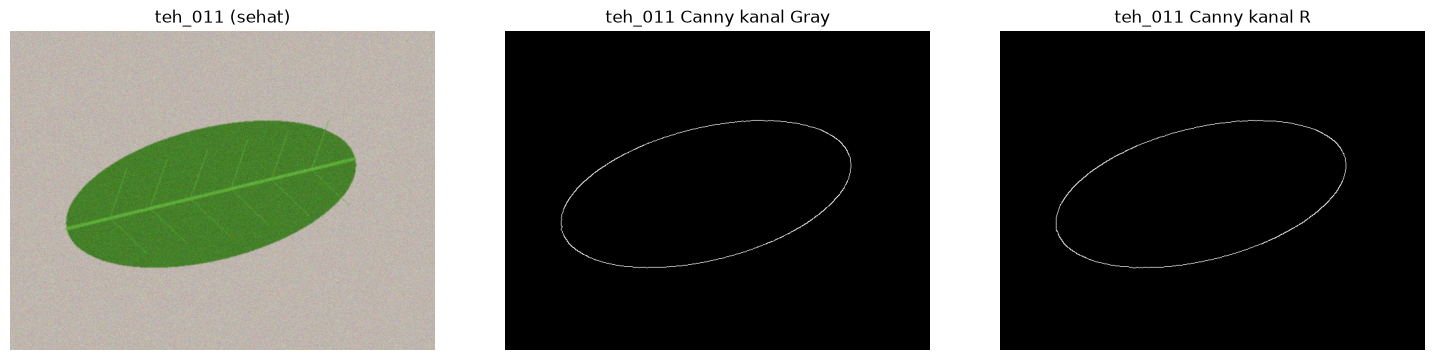

In [18]:
baris, panel, judul = [], [], []
for _, d in label[label.kelas == "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)
    pra_ = praproses(img, PARAM)
    dalam = cv2.erode(md, np.ones((7, 7), np.uint8)) > 0     # bagian dalam daun
    for kanal, g in [("Gray", cv2.cvtColor(pra_, cv2.COLOR_BGR2GRAY)), ("R", pra_[:, :, 2])]:
        e = tepi_canny(g)
        baris.append([d.kondisi_cahaya, kanal, int(((e > 0) & dalam).sum())])
        if d.nama_file == "teh_011.png":
            panel.append(e); judul.append(f"teh_011 Canny kanal {kanal}")
sehat = pd.DataFrame(baris, columns=["kondisi", "kanal", "piksel_tepi_di_dalam_daun"])
print(sehat.pivot_table(index="kondisi", columns="kanal", values="piksel_tepi_di_dalam_daun").loc[urut_kondisi].round(1))
tampil([muat("teh_011.png")[0]] + panel, ["teh_011 (sehat)"] + judul, ukuran=(15, 3.6))
plt.savefig("../hasil/p5_sehat_tepi_dalam.png", dpi=130, bbox_inches="tight")
sehat.to_csv("../hasil/p5_tepi_daun_sehat.csv", index=False)

Tambahan: panel dua daun sehat kondisi gelap (teh_012 dan teh_017), serta ukuran tulang daun pada tiap kanal.

kondisi_cahaya
bayangan          [teh_005.png, teh_010.png, teh_015.png, teh_02...
gelap             [teh_002.png, teh_007.png, teh_012.png, teh_01...
kontras_rendah    [teh_004.png, teh_009.png, teh_014.png, teh_01...
normal            [teh_001.png, teh_006.png, teh_011.png, teh_01...
terang            [teh_003.png, teh_008.png, teh_013.png, teh_01...
Name: nama_file, dtype: object


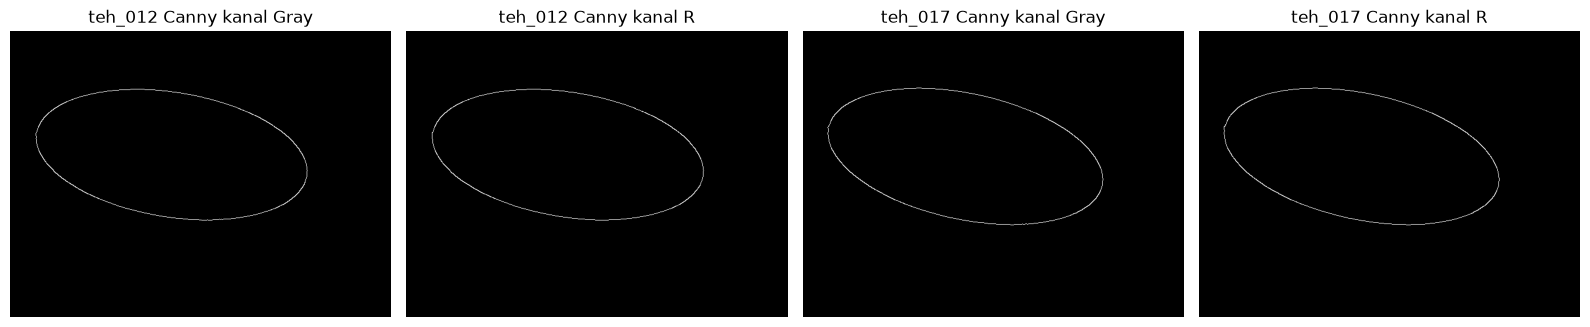

In [19]:
# Tambahan: teh_011 berkondisi "normal" sehingga tulang daun tidak muncul; tampilkan juga daun sehat kondisi gelap
panel, judul = [], []
for nama in ["teh_012.png", "teh_017.png"]:
    img, md, mb = muat(nama); pra_ = praproses(img, PARAM)
    for kanal, g in [("Gray", cv2.cvtColor(pra_, cv2.COLOR_BGR2GRAY)), ("R", pra_[:, :, 2])]:
        panel.append(tepi_canny(g)); judul.append(f"{nama[:7]} Canny kanal {kanal}")
tampil(panel, judul, baris=1, ukuran=(16, 3.2))
plt.savefig("../hasil/p5_sehat_tepi_gelap.png", dpi=130, bbox_inches="tight")
print(label[label.kelas == "sehat"].groupby("kondisi_cahaya").nama_file.apply(list))

In [20]:
# Pendukung P2.5: mengapa tulang daun muncul di Gray tetapi tidak di R (daun sehat kondisi gelap)
baris = []
for nama in label[(label.kelas == "sehat") & (label.kondisi_cahaya == "gelap")].nama_file:
    img, md, mb = muat(nama); pra_ = praproses(img, PARAM)
    dalam = cv2.erode(md, np.ones((7, 7), np.uint8)) > 0
    gray = cv2.cvtColor(pra_, cv2.COLOR_BGR2GRAY)
    e_gray, e_r = tepi_canny(gray), tepi_canny(pra_[:, :, 2])
    tulang = (e_gray > 0) & dalam                           # piksel yang dianggap tulang daun oleh kanal Gray
    if tulang.sum() == 0:
        baris.append([nama, 0, int(((e_r > 0) & dalam).sum()), np.nan, np.nan, np.nan]); continue
    grad = {}
    for nm, c in [("G", pra_[:, :, 1]), ("R", pra_[:, :, 2]), ("Gray", gray)]:
        b = cv2.GaussianBlur(c, (0, 0), 2.0).astype(np.float32)
        grad[nm] = float((np.abs(cv2.Sobel(b, cv2.CV_32F, 1, 0)) + np.abs(cv2.Sobel(b, cv2.CV_32F, 0, 1)))[tulang].mean())
    baris.append([nama, int(tulang.sum()), int(((e_r > 0) & dalam).sum()), grad["G"], grad["R"], grad["Gray"]])
print(pd.DataFrame(baris, columns=["file", "piksel_tepi_dalam_Gray", "piksel_tepi_dalam_R",
                                   "gradien_G", "gradien_R", "gradien_Gray"]).round(1))

          file  piksel_tepi_dalam_Gray  piksel_tepi_dalam_R  gradien_G  gradien_R  gradien_Gray
0  teh_002.png                       0                    0        NaN        NaN           NaN
1  teh_007.png                       0                    0        NaN        NaN           NaN
2  teh_012.png                       0                    0        NaN        NaN           NaN
3  teh_017.png                       0                    0        NaN        NaN           NaN


### Data pendukung untuk P2.3 dan P2.6

In [21]:
# Pendukung P2.3: ambang Canny vs besar gradien di tepi daun pada citra kontras rendah.
# cv2.Canny membandingkan ambang dengan |Gx| + |Gy| (norma L1), maka ukuran yang sama dipakai di sini.
def mag_l1(g):
    gf = g.astype(np.float32)
    return np.abs(cv2.Sobel(gf, cv2.CV_32F, 1, 0)) + np.abs(cv2.Sobel(gf, cv2.CV_32F, 0, 1))

baris = []
for _, d in label[(label.kelas != "sehat") & (label.kondisi_cahaya == "kontras_rendah")].iterrows():
    img, md, mb = muat(d.nama_file)
    pra_ = praproses(img, PARAM)
    tp = tepi_acuan(md) > 0                                   # tepi daun acuan
    for kanal, g in [("Gray", cv2.cvtColor(pra_, cv2.COLOR_BGR2GRAY)), ("R", pra_[:, :, 2])]:
        v = np.median(g)
        lo_o, hi_o = int(max(0, 0.67 * v)), int(min(255, 1.33 * v))   # ambang otomatis (s = 0,33)
        m0 = mag_l1(g)[tp]                                        # tanpa penghalusan (dipakai canny_otomatis)
        m2 = mag_l1(cv2.GaussianBlur(g, (0, 0), 2.0))[tp]         # sesudah Gaussian sigma 2 (dipakai tepi_canny)
        baris.append([d.nama_file, kanal, v, lo_o, hi_o, np.median(m0), (m0 >= hi_o).mean(),
                      np.median(m2), np.percentile(m2, 90), (m2 >= 90).mean(), (m2 >= 30).mean()])
t = pd.DataFrame(baris, columns=["file", "kanal", "median_intensitas", "lo_otomatis", "hi_otomatis",
                                 "grad_tepi_median", "porsi_tepi>=hi_otomatis",
                                 "grad_tepi_median_sigma2", "grad_tepi_p90_sigma2", "porsi>=90", "porsi>=30"])
ring = t.groupby("kanal").mean(numeric_only=True).round(3)
print(ring.T)
ring.to_csv("../hasil/p5_ambang_kontras_rendah.csv")

kanal                       Gray        R
median_intensitas        161.625  164.000
lo_otomatis              107.750  109.250
hi_otomatis              214.500  217.750
grad_tepi_median          94.125  148.250
porsi_tepi>=hi_otomatis    0.000    0.063
grad_tepi_median_sigma2   54.750   85.250
grad_tepi_p90_sigma2      63.250   98.250
porsi>=90                  0.000    0.356
porsi>=30                  0.982    0.988


In [22]:
# Pendukung P2.6: tepi saja belum memberi luas bercak; ukur korelasi, perkiraan luas dari keliling, dan waktu proses
import time
baris = []
for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file)
    t0 = time.perf_counter()
    pra_ = praproses(img, PARAM)
    t1 = time.perf_counter()
    e = tepi_canny(pra_[:, :, 2])
    t2 = time.perf_counter()
    dalam = cv2.erode(md, np.ones((7, 7), np.uint8)) > 0
    n_tepi = int(((e > 0) & dalam).sum())
    luas_nyata = int((mb > 0).sum())
    baris.append([d.nama_file, d.kelas, d.persen_bercak, n_tepi, luas_nyata, int((md > 0).sum()),
                  1000 * (t1 - t0), 1000 * (t2 - t1)])
x = pd.DataFrame(baris, columns=["file", "kelas", "persen_bercak", "piksel_tepi_dalam", "luas_bercak_px",
                                 "luas_daun_px", "ms_praproses", "ms_canny"])
print("korelasi persen_bercak vs piksel tepi (seluruh data)   :", round(x.persen_bercak.corr(x.piksel_tepi_dalam), 3))
for k in ["ringan", "berat"]:
    xx = x[x.kelas == k]
    print(f"korelasi di dalam kelas {k:6s}                         :", round(xx.persen_bercak.corr(xx.piksel_tepi_dalam), 3))
# taksiran paling sederhana: seluruh keliling dianggap satu lingkaran -> luas = keliling^2 / (4 pi)
b = x[x.kelas != "sehat"].copy()
b["persen_dari_tepi"] = 100 * (b.piksel_tepi_dalam ** 2 / (4 * np.pi)) / b.luas_daun_px
print("galat absolut persen bercak bila luas ditaksir dari keliling saja: %.2f poin (rerata persen sebenarnya %.2f)" %
      ((b.persen_dari_tepi - b.persen_bercak).abs().mean(), b.persen_bercak.mean()))
print(x.groupby("kelas")[["persen_bercak", "piksel_tepi_dalam"]].mean().round(2))
print("\nwaktu rerata per citra (ms): praproses = %.1f | Canny = %.1f" % (x.ms_praproses.mean(), x.ms_canny.mean()))
x.to_csv("../hasil/p5_tepi_vs_persen.csv", index=False)

korelasi persen_bercak vs piksel tepi (seluruh data)   : 0.966
korelasi di dalam kelas ringan                         : 0.698
korelasi di dalam kelas berat                          : 0.585
galat absolut persen bercak bila luas ditaksir dari keliling saja: 19.70 poin (rerata persen sebenarnya 3.07)
        persen_bercak  piksel_tepi_dalam
kelas                                   
berat            5.70             631.55
ringan           0.44              66.15
sehat            0.00               0.00

waktu rerata per citra (ms): praproses = 0.5 | Canny = 0.9


### Langkah 2.6 (kerjakan sendiri) Keputusan pemakaian deteksi tepi

**Tabel 8.** Keputusan pemakaian deteksi tepi pada SIMUTEH

| Keperluan | Dipakai? (ya/tidak) | Operator dan parameter | Bukti (rujuk tabel atau gambar) |
|---|---|---|---|
| Menemukan batas daun | **Ya** (verifikasi dan kontur daun; luas daun untuk penyebut persen tetap dari mask daun) | Canny kanal R, sigma 2, ambang 30/90 | Tabel 6: F1 0,985 (kanal R, praproses); Tabel 7: sigma 2, 30/90 memberi F1 tertinggi 0,985 (P 0,988, R 0,981); Gambar 2 dan Gambar 3: F1 0,963-0,996 di semua kondisi cahaya |
| Menemukan batas bercak | **Ya** | Canny kanal R, **sigma 1**, ambang 30/90 (alternatif `canny_persentil` q = 98 bila kontras berubah-ubah) | Tabel 7: sigma 1, 30/90 memberi F1 0,964 dan R bercak ringan 0,850 (sigma 2: 0,792; sigma 0 hanya 0,906 tetapi presisi 0,311); R bercak berat 0,976; tabel pembanding ambang: q = 98 kanal R F1 0,990 (kontras rendah 0,985) |
| Mengisi wilayah bercak (segmentasi) | **Tidak** (tepi hanya garis kontur, bukan wilayah) | Diganti isian kontur, morfologi, dan komponen terhubung (P6-P7) | Keluaran X_P26: persen bercak vs piksel tepi hanya berkorelasi 0,686 (ringan) dan 0,535 (berat) di dalam kelas; taksiran luas dari keliling saja salah 19,63 poin (rerata persen sebenarnya 3,07) |
| Fitur bentuk bercak (P9) | **Ya** (kontur sebagai bahan keliling dan kebulatan, setelah bercak dilabeli) | Canny kanal R, sigma 1, 30/90, lalu kontur per komponen | Tabel 7 (R bercak berat 0,976); Gambar 2: lingkaran bercak tampak utuh pada Canny; keterbatasan: bercak yang menyatu tampak sebagai satu kontur |

Catatan keputusan: kanal **R** dipilih untuk semua keperluan, bukan Gray, karena KB lebih tinggi (P1.3), F1 stabil di kondisi kontras rendah (Gray 0,000), dan tidak memunculkan tulang daun sebagai tepi palsu (P2.5).

### Jawaban Pertanyaan Analisis Bagian 2

**P2.1.** NMS membandingkan piksel dengan tetangga **searah gradien** karena gradien tegak lurus terhadap tepi: dua tetangga searah gradien berada di dua sisi tepi, sehingga membandingkannya menjawab pertanyaan "apakah piksel ini puncak penampang tepi?". Bila dibandingkan searah tepi, yang dibandingkan hanyalah piksel-piksel tepi lain yang kekuatannya mirip sehingga garis tebal tidak pernah ditipiskan. Contoh soal (a): M2 pusat 80 memiliki tetangga searah gradien 0 derajat sebesar 85 > 80, jadi pusat bukan puncak dan ditekan; M1 pusat 100 lebih besar dari kedua tetangganya sehingga dipertahankan. Hysteresis memakai **dua ambang** karena satu ambang selalu merugikan: ambang tinggi memutus tepi yang melemah di sebagian titik, ambang rendah memasukkan derau. Dengan dua ambang, piksel kuat menjadi "benih" dan piksel lemah hanya diterima bila terhubung ke benih. Piksel bernilai 90 pada soal (b) dibuang walau lebih besar dari ambang bawah (50) karena **tidak terhubung ke piksel kuat**: tetangganya, 40 dan 30, berada di bawah ambang bawah sehingga ia terisolasi (ciri derau atau tepi pendek).

**P2.2.** Dari Tabel 7, F1 tertinggi dicapai **sigma 2 dengan ambang 30/90** (F1 0,985; P 0,988; R 0,981). Kombinasi itu **bukan yang terbaik untuk bercak ringan**: R bercak ringan hanya 0,792 (berat 0,952). R bercak ringan tertinggi memang sigma 0 / 30/90 (0,906) tetapi presisinya 0,311 (F1 0,388) sehingga derau ikut terdeteksi dan tidak dapat dipakai. Kompromi yang lebih baik untuk bercak ringan adalah **sigma 1 / 30/90**: F1 0,964, presisi 0,943, R bercak ringan 0,850 dan berat 0,976. Trade-off: sigma besar meredam derau (presisi naik) tetapi juga melandaikan gradien bercak yang kecil dan berkontras rendah (bercak ringan hanya 0,2-0,8% luas daun), sehingga recall bercak kecil turun. Hal yang sama terjadi pada ambang tinggi: sigma 2 dengan 100/200 hanya mempertahankan 0,231 tepi bercak ringan dan 0,484 bercak berat. Bercak kecil yang hilang di tahap tepi berarti kelas ringan terbaca sehat, jadi pada SIMUTEH recall bercak kecil layak diutamakan sedikit di atas presisi.

**P2.3.** Pada citra kontras rendah kanal Gray (rerata 8 citra), median intensitas 161,6 sehingga ambang otomatis = 0,67 x 161,6 = **108** dan 1,33 x 161,6 = **214**. Gradien |Gx|+|Gy| di tepi daun hanya bermedian 98,4 dan **0% piksel tepi** mencapai 214, maka tidak ada benih tepi kuat, sehingga tidak ada tepi (F1 = 0,000). Ambang tetap 30/90 dengan sigma 2 juga gagal: sesudah Gaussian gradien tepi daun bermedian 55,0 (persentil ke-90 hanya 63,5); 98,3% piksel tepi lolos ambang bawah 30 tetapi **0%** mencapai ambang atas 90, jadi lagi-lagi tidak ada benih (F1 = 0,000). Pada kanal R median intensitas 161,9 (ambang 108/215) tetapi gradien tepi daun bermedian 157,8 dan **12,9%** piksel tepi melampaui 215, sehingga ada benih dan hysteresis menyambung sisanya (F1 otomatis 0,900); pada ambang tetap sesudah sigma 2 gradien bermedian 85,3, 36,8% piksel tepi >= 90 (F1 0,963). Jadi gradien tepi daun di kanal R sekitar 1,6 kali lipat lebih besar daripada di Gray (157,8 vs 98,4), sehingga gagal-tidaknya tergantung apakah ada benih di atas ambang atas. Ambang dari median **intensitas** tidak cocok untuk Canny karena Canny bekerja pada **magnitudo gradien** (selisih intensitas antartetangga), bukan pada tingkat keabuan: median 161 hanya mencerminkan citra yang terang karena latar pucat dominan, dan tidak mengandung informasi tentang setajam apa tepinya. Ambang yang berpatokan pada kecerahan akan bergeser mengikuti cahaya (median kanal R: gelap 163, terang 227, bayangan 113) padahal besar gradien tepi tidak bergeser sebanding; hasilnya F1 otomatis lebih rendah daripada ambang tetap pada Gray gelap (0,876 vs 0,908) dan terang (0,891 vs 0,965), dan pada kanal R rerata 0,963 vs 0,985.

**P2.4.** Persentil magnitudo mengikuti **distribusi gradien citra itu sendiri**: bila kontras turun, semua magnitudo mengecil dan persentil ke-q ikut mengecil, sehingga proporsi piksel yang dianggap kuat tetap (100 - q)%, sedangkan ambang tetap atau ambang dari intensitas tidak ikut menyesuaikan. Buktinya pada kondisi kontras rendah: q = 98 menghasilkan F1 0,985 (kanal R) dan 0,872 (Gray), dibanding otomatis 0,900 dan 0,000, atau tetap 30/90 0,963 dan 0,000; rerata lima kondisi kanal R = 0,990 (tetap 0,985; otomatis 0,963). Nilai q yang tepat berkaitan dengan **proporsi piksel tepi**: piksel tepi acuan hanya 0,58% citra (0,41-0,82%). Dengan q = 90 sebanyak 10% piksel dianggap kuat sehingga tekstur dan derau ikut menjadi tepi (F1 0,07), q = 95 (5%) F1 0,47 (R) dan 0,53 (Gray), q = 98 (2%) F1 0,990 (R), q = 99 (1%) F1 0,967 (R) dan 0,929 (Gray, terbaik untuk Gray), dan q = 99,5 recall turun menjadi 0,836 (F1 0,902). Jadi (100 - q) sebaiknya sekitar 1 sampai 3 kali proporsi tepi yang diharapkan, yaitu q sekitar 98-99 untuk dataset ini.

**P2.5.** Pada Kode 2.3, **kanal R tidak menghasilkan satu pun piksel tepi di dalam daun sehat pada semua kondisi** (0 piksel), sedangkan kanal Gray juga 0 piksel pada kondisi normal, terang, kontras rendah, dan bayangan, tetapi rata-rata 113,8 piksel pada kondisi gelap. Penyebabnya hanya satu citra: teh_017 (kondisi gelap) memunculkan garis tulang daun utuh sepanjang 455 piksel di Gray (teh_002, teh_007, teh_012 tidak), dan teh_011 yang dipakai petunjuk berkondisi normal sehingga bersih di kedua kanal. Pengukuran gradien pada piksel tulang daun di teh_017 (sesudah Gaussian sigma 2): kanal G 87,8, Gray 60,6, tetapi kanal R hanya **23,9**, di bawah ambang bawah Canny (30) sehingga tidak diterima. Artinya tulang daun (hijau lebih muda) menonjol di kanal G yang ikut membentuk Gray, sedangkan di kanal R nilainya hampir sama dengan daun di sekitarnya. Bagi SIMUTEH: **kanal R lebih aman untuk deteksi tepi** karena tidak menciptakan "bercak palsu" dari tulang daun (masalah yang tercatat pada evaluasi P5.3), dan sekaligus KB-nya lebih tinggi. Keterbatasan: bukti ini hanya dari satu daun sehat (1 dari 20), pada data sintetis.

**P2.6.** Keputusan pada Tabel 8: tepi dipakai untuk menemukan batas daun, batas bercak, dan bahan fitur bentuk, tetapi **tidak** untuk mengisi wilayah bercak. Tepi hanya berupa garis setebal sekitar 1 piksel, sedangkan persentase bercak = luas bercak / luas daun x 100 memerlukan **luas wilayah**. Bukti: korelasi persen bercak dengan jumlah piksel tepi tampak tinggi secara keseluruhan (0,962), tetapi itu hanya karena perbedaan kelas; di dalam kelas turun menjadi 0,686 (ringan) dan 0,535 (berat), dan bila luas ditaksir dari keliling saja (dianggap satu lingkaran) galatnya 19,63 poin padahal rerata persen bercak sebenarnya hanya 3,07. Alasannya keliling tumbuh sebanding akar luas, jumlah bercak tidak diketahui, dan bercak yang menyatu (tampak pada teh_041) menghasilkan satu kontur. Maka perlu langkah lanjutan: isi kontur atau ambang, morfologi, lalu komponen terhubung (P6). Kaitannya dengan kebutuhan pengguna: **nomor 2 (keluaran persen bercak)** menuntut luas wilayah sehingga tepi saja belum cukup, sedangkan **nomor 4 (proses cepat)** terpenuhi karena praproses + Canny pada citra 640 x 480 hanya sekitar 0,3 ms dan kurang dari 1 ms per citra di mesin uji ini (angka pada ponsel akan lebih besar dan perlu diuji sendiri). Tepi dengan demikian cocok sebagai tahap awal yang murah, dilengkapi pengisian wilayah pada Pertemuan 6.

### Hasil yang harus ada (Bagian 1 dan 2)

- [x] Lembar hitung 1.1 dan 2.1 lengkap dengan langkah dan verifikasi kode
- [x] Keluaran Kode 1.2 (selisih manual vs `cv2.Sobel` = 0,0) dan panel Gx, Gy, magnitudo, arah (`hasil/p5_gradien_sobel.png`)
- [x] Panel empat operator (`hasil/p5_empat_operator.png`), Tabel 6, `hasil/p5_tabel_tepi.csv`
- [x] Grafik F1 per kondisi cahaya (`hasil/p5_f1_kondisi.png`)
- [x] Tabel 7 dan keluaran Kode 2.2 serta 2.3
- [x] Fungsi `canny_persentil` dan tabel F1 per kondisi (`hasil/p5_banding_ambang_otomatis.csv`)
- [x] Tabel 8
- [ ] Langkah 2.7: commit dan tag `v0.2-tepi` (dilakukan di repositori lokal Anda)